# Prédiction des performances d'allocations d'actifs

Le benchmark LightGBM fourni par QRT est à 0.5079 en public. Ce notebook reprend le même
déroulé (lecture des fichiers, features, ridge, lightgbm en cross validation, soumission)
avec deux étapes ajoutées en amont, parce qu'elles changent la suite.

La première est un contrôle des baselines. La classe positive est à 50.7%, donc prédire 1
partout donne 0.5072 et ne suffit pas. Le signal conditionnel existe mais il est faible,
ce qui impose de la régularisation et une validation soignée. Il vient presque entièrement
du momentum à un jour, et ce qui l'enrichit vraiment est que ce momentum n'a pas la même
force selon l'allocation.

La seconde est la reconstruction de l'ordre chronologique des dates. Les labels DATE_xxxx
sont mélangés, mais les fenêtres de 20 jours de deux dates consécutives se recouvrent sur
19 valeurs, ce qui permet de rechaîner les dates. Sur l'entraînement cela redonne la cible
à 0.92 d'accuracy. Sur le test la chaîne ne se referme pas, aucune date de test n'ayant de
voisine à moins de douze jours. La reconstruction sert donc uniquement à découper une
validation croisée honnête, ce qui est impossible autrement puisqu'on ne connaît pas
l'ordre des dates.

### Reproduire ce notebook

Quatre fichiers sont attendus dans le dossier courant, sous les noms standard du challenge :
X_train.csv, y_train.csv, X_test.csv et sample_submission.csv.

Dependances : numpy, pandas, scipy, scikit-learn, lightgbm, matplotlib, seaborn. Les versions
utilisees sont affichees a la derniere cellule.

Executer toutes les cellules dans l'ordre regenere submission.csv, qui est le fichier a
deposer sur la plateforme. Le notebook ne lit ni n'ecrit rien d'autre. Compter une trentaine
de minutes sur quatre coeurs, dont l'essentiel dans la cellule de cross validation LightGBM.

Chaque cellule affiche son temps d'execution.

### Imports

In [1]:
%%time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import lightgbm as lgbm
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from scipy.optimize import linear_sum_assignment

import time, sys, platform
DEBUT = time.time()

RET_features = [f'RET_{i}' for i in range(1, 21)]
SIGNED_VOLUME_features = [f'SIGNED_VOLUME_{i}' for i in range(1, 21)]

CPU times: user 3.4 s, sys: 678 ms, total: 4.08 s
Wall time: 5.87 s


### Lecture des fichiers

In [2]:
%%time
X_train = pd.read_csv('X_train.csv', index_col='ROW_ID')
X_test  = pd.read_csv('X_test.csv',  index_col='ROW_ID')
y_train = pd.read_csv('y_train.csv', index_col='ROW_ID').target
sample_submission = pd.read_csv('sample_submission.csv')

print(X_train.shape, X_test.shape)
print('dates train :', X_train.TS.nunique(), X_train.TS.min(), X_train.TS.max())
print('dates test  :', X_test.TS.nunique(),  X_test.TS.min(),  X_test.TS.max())
print('dates communes :', len(set(X_train.TS) & set(X_test.TS)))
print('allocations    :', X_train.ALLOCATION.nunique(), X_test.ALLOCATION.nunique())

(527073, 44) (31870, 44)
dates train : 2522 DATE_0001 DATE_2522
dates test  : 120 DATE_2523 DATE_2642


dates communes : 0
allocations    : 278 278
CPU times: user 7.84 s, sys: 456 ms, total: 8.29 s
Wall time: 8.35 s


In [3]:
%%time
# SIGNED_VOLUME_1 est manquant trois fois sur quatre, la veille n'est pas encore consolidee.
# On s'en sert comme rappel de ne pas construire de feature dessus.
na = X_train.isna().mean().sort_values(ascending=False)
print(na[na > 0.001].round(4).to_string())

SIGNED_VOLUME_1          0.7352
SIGNED_VOLUME_20         0.0161
MEDIAN_DAILY_TURNOVER    0.0069
SIGNED_VOLUME_19         0.0057
SIGNED_VOLUME_18         0.0016
CPU times: user 40.5 ms, sys: 13.1 ms, total: 53.6 ms
Wall time: 51.4 ms


### Premiers repères

In [4]:
%%time
pos = (y_train > 0).astype(int)
print('P(target > 0)                      :', round(pos.mean(), 4))
print('accuracy si on predit 1 partout    :', round(pos.mean(), 4))
print('benchmark lgbm de reference        : 0.5079')

P(target > 0)                      : 0.5072
accuracy si on predit 1 partout    : 0.5072
benchmark lgbm de reference        : 0.5079
CPU times: user 5.4 ms, sys: 3.55 ms, total: 8.95 ms
Wall time: 6.3 ms


Le taux de base ne bat pas le benchmark, contrairement à ce qu'on pourrait attendre de
stratégies construites pour gagner de l'argent. Il faut donc un vrai modèle.

Deuxième repère, la part du mouvement commun à toutes les allocations d'une même journée.
Toutes les lignes d'une date partagent le même vecteur de rendements d'actifs, on s'attend
donc à une forte corrélation cross-sectionnelle.

In [5]:
%%time
tmp = pd.DataFrame({'TS': X_train.TS, 'y': y_train, 'pos': pos})
demeaned = tmp.y - tmp.groupby('TS').y.transform('mean')
print('part de variance portee par l effet date :', round(1 - demeaned.var() / tmp.y.var(), 4))

frac_pos = tmp.groupby('TS').pos.mean()
n_par_date = tmp.groupby('TS').size()
plafond = (np.maximum(frac_pos, 1 - frac_pos) * n_par_date).sum() / len(tmp)
print('accuracy si on connaissait le signe majoritaire de chaque jour :', round(plafond, 4))

part de variance portee par l effet date : 0.066
accuracy si on connaissait le signe majoritaire de chaque jour : 0.5716
CPU times: user 91.3 ms, sys: 16.7 ms, total: 108 ms
Wall time: 105 ms


L'effet date ne pèse que 6.6% de la variance, et même en connaissant parfaitement la
direction de chaque journée on plafonnerait à 0.5716. Le mouvement commun est donc bien
moins dominant qu'attendu, et l'essentiel de ce qui est prédictible se joue au niveau de
chaque allocation. C'est plutôt une bonne nouvelle, on peut travailler ligne par ligne.

Reste à voir quels signaux bruts portent quelque chose.

In [6]:
%%time
r = X_train[RET_features].to_numpy(float)
signaux = pd.DataFrame({
    'RET_1': r[:, 0],
    'RET_2': r[:, 1],
    'RET_3': r[:, 2],
    'mom5' : np.nanmean(r[:, :5], 1),
    'mom20': np.nanmean(r, 1),
    'MEDIAN_DAILY_TURNOVER': X_train.MEDIAN_DAILY_TURNOVER,
})
for c in signaux.columns:
    v = signaux[c]
    ok = v.notna()
    print(f'{c:24s} corr = {np.corrcoef(v[ok], y_train[ok])[0, 1]:+.4f}   '
          f'accuracy du signe = {accuracy_score(pos[ok], (v[ok] > 0).astype(int)):.4f}')

RET_1                    corr = +0.0849   accuracy du signe = 0.5189
RET_2                    corr = -0.0090   accuracy du signe = 0.4975
RET_3                    corr = -0.0121   accuracy du signe = 0.4995
mom5                     corr = +0.0164   accuracy du signe = 0.5056
mom20                    corr = +0.0276   accuracy du signe = 0.5082


MEDIAN_DAILY_TURNOVER    corr = +0.0134   accuracy du signe = 0.5072
CPU times: user 452 ms, sys: 119 ms, total: 572 ms
Wall time: 585 ms


Presque tout est dans RET_1. Le momentum à un jour donne 0.5189 à lui seul, soit déjà plus
que le benchmark. Les autres retards individuels n'apportent rien, et le turnover médian
non plus directement. Ça fixe l'ordre de grandeur de ce qu'on peut espérer.

### Reconstruction de l'ordre des dates

L'énoncé prévient que les labels de dates sont anonymisés et sans garantie de continuité.
On le vérifie d'abord, puis on cherche à retrouver l'ordre réel.

Si $t'$ est le lendemain de $t$, alors pour une même allocation la fenêtre glisse d'un cran :

$$\text{RET}_{i+1}(t') = \text{RET}_i(t), \qquad i = 1 \dots 19$$

et surtout $\text{RET}_1(t')$ est le rendement du jour $t+1$, c'est à dire la cible de $t$.

In [7]:
%%time
# Les labels ne sont pas chronologiques : DATE_0002 n'est pas le lendemain de DATE_0001.
t = X_train[['TS', 'ALLOCATION', 'RET_1']].copy()
t['tnum'] = t.TS.str.slice(5).astype(int)
t['target'] = y_train
suivant = t.assign(tnum=t.tnum - 1)[['tnum', 'ALLOCATION', 'RET_1']]
m = t.merge(suivant, on=['tnum', 'ALLOCATION'], suffixes=('', '_next'))

print('en supposant les labels ordonnes, target(t) vs RET_1(t+1) :')
print('   fraction egales a 1e-6 pres :', round((m.target - m.RET_1_next).abs().lt(1e-6).mean(), 5))
print('   accord de signe             :', round(((m.target > 0) == (m.RET_1_next > 0)).mean(), 4))

en supposant les labels ordonnes, target(t) vs RET_1(t+1) :
   fraction egales a 1e-6 pres : 0.00025
   accord de signe             : 0.5017
CPU times: user 237 ms, sys: 53.2 ms, total: 290 ms
Wall time: 288 ms


Aucun lien, on est au niveau du hasard. Les labels sont donc bien permutés.

Le rechaînage par égalité exacte ne fonctionne pas non plus, les rendements ont été
légèrement bruités à l'anonymisation. Par contre le recouvrement de 19 valeurs reste très
visible si on compare les dates sur l'ensemble des 278 allocations à la fois, en utilisant
un cosinus plutôt qu'une égalité.

In [8]:
%%time
# Tenseur (date, allocation, retard) sur train et test reunis.
A = pd.concat([X_train.assign(_test=0), X_test.assign(_test=1)])
dates  = np.sort(A.TS.unique())
allocs = np.sort(A.ALLOCATION.unique())
d_pos = {d: i for i, d in enumerate(dates)}
a_pos = {a: i for i, a in enumerate(allocs)}
ND, NA = len(dates), len(allocs)

V = np.full((ND, NA, 20), np.nan)
V[A.TS.map(d_pos).values, A.ALLOCATION.map(a_pos).values] = A[RET_features].to_numpy(float)
dispo = ~np.isnan(V).any(2)
print('tenseur', V.shape, ', couples renseignes', round(dispo.mean(), 3))

tenseur (2642, 278, 20) , couples renseignes 0.761
CPU times: user 388 ms, sys: 149 ms, total: 536 ms
Wall time: 536 ms


In [9]:
%%time
def bloc(tranche):
    """Chaque couple (date, allocation) est ramene a la norme 1.
    Le produit scalaire entre deux dates devient alors un cosinus moyen par allocation."""
    M = V[:, :, tranche].copy()
    norme = np.linalg.norm(np.nan_to_num(M), axis=2, keepdims=True)
    M = np.nan_to_num(M) / np.maximum(norme, 1e-300)
    M[~dispo] = 0
    return M.reshape(ND, -1)

paires = dispo.astype(float) @ dispo.astype(float).T   # nb d'allocations communes
Sim = (bloc(slice(0, 19)) @ bloc(slice(1, 20)).T) / np.maximum(paires, 1)
np.fill_diagonal(Sim, -9)

meilleur = Sim.max(1)
second   = np.partition(Sim, -2, axis=1)[:, -2]
print('similarite du meilleur candidat, mediane :', round(np.median(meilleur), 4))
print('ecart entre le meilleur et le second     :', round(np.median(meilleur - second), 4))

similarite du meilleur candidat, mediane : 0.9836
ecart entre le meilleur et le second     : 0.785
CPU times: user 5.32 s, sys: 279 ms, total: 5.6 s
Wall time: 2.17 s


Le meilleur candidat sort à 0.98 et le second à 0.20. Le successeur d'une date est donc
identifié sans ambiguïté. On peut résoudre proprement l'affectation, chaque date ayant un
successeur et un seul.

In [10]:
%%time
ligne, colonne = linear_sum_assignment(-Sim)
succ = np.empty(ND, int)
succ[ligne] = colonne
qualite = Sim[np.arange(ND), succ]

est_test = np.isin(dates, X_test.TS.unique())
print('liens train : qualite moyenne %.4f, liens douteux %d sur %d'
      % (qualite[~est_test].mean(), (qualite[~est_test] < 0.9).sum(), (~est_test).sum()))
print('liens test  : qualite moyenne %.4f, liens douteux %d sur %d'
      % (qualite[est_test].mean(),  (qualite[est_test]  < 0.9).sum(), est_test.sum()))

liens train : qualite moyenne 0.9782, liens douteux 22 sur 2522
liens test  : qualite moyenne 0.1070, liens douteux 120 sur 120
CPU times: user 175 ms, sys: 8.32 ms, total: 183 ms
Wall time: 182 ms


Sur l'entraînement la chaîne se referme presque partout, 22 liens douteux sur 2522.
Sur le test aucun lien ne tient. Les deux blocs se comportent différemment, on regarde
d'abord ce que vaut la chaîne là où elle marche.

In [11]:
%%time
# La cible de t se retrouve en RET_1 du successeur, en RET_2 du successeur du successeur,
# et ainsi de suite. Autant d'estimations bruitees de la meme quantite.
d_idx = X_train.TS.map(d_pos).values
a_idx = X_train.ALLOCATION.map(a_pos).values

etape = np.arange(ND)
E = []
for k in range(1, 6):
    etape = succ[etape]
    E.append(V[etape, :, k - 1][d_idx, a_idx])
E = np.array(E)

for k in range(3):
    ok = ~np.isnan(E[k])
    print(f'retard {k+1} seul : accuracy = {accuracy_score(pos[ok], (E[k][ok] > 0).astype(int)):.4f}')

complet = ~np.isnan(E[:3]).any(0)
poids = np.linalg.lstsq(E[:3, complet].T, y_train.values[complet], rcond=None)[0]
combi = poids @ E[:3, complet]
print('retards 1 a 3 combines :',
      round(accuracy_score(pos[complet], (combi > 0).astype(int)), 4),
      ', poids', np.round(poids, 3))

retard 1 seul : accuracy = 0.8855
retard 2 seul : accuracy = 0.9125
retard 3 seul : accuracy = 0.8929
retards 1 a 3 combines : 0.9245 , poids [0.214 0.492 0.282]
CPU times: user 415 ms, sys: 83 ms, total: 498 ms
Wall time: 490 ms


0.92 sur l'entraînement. Le bruit ajouté aux rendements est corrélé d'un retard à l'autre,
ce qui explique qu'aller au delà du troisième n'apporte plus rien.

Reste la question qui décide de tout : est ce que les dates de test se chaînent entre elles ?
On ne se limite pas à des dates consécutives, on teste tous les écarts possibles. Avec un
écart de g jours le recouvrement porte sur 20 - g valeurs, et la cible de t se lit en
RET_g de la date située g jours plus tard. On s'arrête à g = 12, au delà il reste trop peu
de valeurs communes pour que le cosinus discrimine quoi que ce soit.

In [12]:
%%time
idx_test = np.where(est_test)[0]
idx_train = np.where(~est_test)[0]

for g in [1, 2, 3, 5, 8, 10, 12]:
    Sg = (bloc(slice(0, 20 - g)) @ bloc(slice(g, 20)).T) / np.maximum(paires, 1)
    np.fill_diagonal(Sg, -9)
    print(f'ecart {g:2d} jours : test vers tout = {Sg[idx_test].max():.3f} , '
          f'tout vers test = {Sg[:, idx_test].max():.3f} , '
          f'train vers train = {Sg[np.ix_(idx_train, idx_train)].max():.3f}')

ecart  1 jours : test vers tout = 0.405 , tout vers test = 0.417 , train vers train = 0.999


ecart  2 jours : test vers tout = 0.445 , tout vers test = 0.366 , train vers train = 0.999


ecart  3 jours : test vers tout = 0.422 , tout vers test = 0.411 , train vers train = 0.999


ecart  5 jours : test vers tout = 0.443 , tout vers test = 0.410 , train vers train = 0.997


ecart  8 jours : test vers tout = 0.470 , tout vers test = 0.438 , train vers train = 0.997


ecart 10 jours : test vers tout = 0.464 , tout vers test = 0.520 , train vers train = 0.998


ecart 12 jours : test vers tout = 0.451 , tout vers test = 0.462 , train vers train = 0.995
CPU times: user 27.9 s, sys: 1.23 s, total: 29.2 s
Wall time: 11.6 s


Pour tous les écarts testés, la meilleure correspondance impliquant une date de test reste
très en dessous de ce qu'on observe entre dates d'entraînement. Aucune date de test n'a de
voisine à moins de douze jours, ni dans le test ni dans le train. Le bloc de test est isolé,
il n'y a rien à récupérer de ce côté et on passe à un vrai modèle.

Ce qu'on garde, c'est l'ordre des dates d'entraînement. Les liens douteux coupent la chaîne
en segments, chacun étant une suite de jours réellement consécutifs.

In [13]:
%%time
Sim_train = Sim[np.ix_(idx_train, idx_train)]
ligne, colonne = linear_sum_assignment(-Sim_train)
succ_train = np.empty(len(idx_train), int)
succ_train[ligne] = colonne
q = Sim_train[np.arange(len(idx_train)), succ_train]

suivant = np.where(q > 0.85, succ_train, -1)
precedent = np.full(len(idx_train), -1)
for i, j in enumerate(suivant):
    if j >= 0:
        precedent[j] = i

segment = np.full(len(idx_train), -1)
rang = np.full(len(idx_train), -1)
s = 0
for depart in list(np.where(precedent == -1)[0]) + list(range(len(idx_train))):
    if segment[depart] != -1:
        continue
    j, p = depart, 0
    while j != -1 and segment[j] == -1:
        segment[j], rang[j] = s, p
        p += 1
        j = suivant[j]
    s += 1

chrono = pd.DataFrame({'TS': dates[idx_train], 'segment': segment, 'rang': rang})
print('nombre de segments :', chrono.segment.nunique())
print('tailles des plus gros :', chrono.segment.value_counts().head(6).tolist())

nombre de segments : 13
tailles des plus gros : [622, 494, 362, 315, 260, 157]
CPU times: user 121 ms, sys: 7.22 ms, total: 128 ms
Wall time: 126 ms


### Features

Le benchmark construit des moyennes de performances passées à plusieurs horizons, leur
équivalent agrégé sur toutes les allocations, et des volatilités. On garde cette logique en
ajoutant quelques blocs.

Le premier est la normalisation par la volatilité. Le signe de RET_1 compte, mais son
amplitude rapportée au risque de l'allocation compte davantage.

Le deuxième est le rang cross-sectionnel dans la journée. On dispose de toute la
cross-section de chaque date de test, donc ces variables se calculent des deux côtés sans
précaution particulière.

Le troisième vient du GROUP. Les allocations d'un même groupe partagent visiblement des
signaux, on calcule leur rendement moyen en excluant l'allocation elle même pour éviter de
recopier sa propre valeur.

Le quatrième est le bêta de l'allocation au rendement moyen des autres, estimé sur la
fenêtre de 20 jours, et le résidu de RET_1 une fois ce bêta retiré.

On s'est limité à 27 variables. Des versions plus fournies ont été essayées, notamment avec
les agrégats de groupe à tous les retards, la corrélation rendement volume et les
interactions avec le turnover. Elles dégradent la validation, le signal est trop faible pour
les supporter.

In [14]:
%%time
def build_features(df):
    r  = df[RET_features].to_numpy(float)
    sv = df[SIGNED_VOLUME_features].to_numpy(float)
    F = pd.DataFrame(index=df.index)

    for i in range(1, 6):
        F[f'RET_{i}'] = r[:, i - 1]
    for h in [5, 10, 20]:
        F[f'mom{h}'] = np.nanmean(r[:, :h], 1)

    F['vol20'] = np.nanstd(r, 1)
    F['vol5']  = np.nanstd(r[:, :5], 1)
    F['zmom1'] = r[:, 0] / F.vol20
    F['zmom5'] = F.mom5  / F.vol20
    F['MDT']   = df.MEDIAN_DAILY_TURNOVER
    F['GROUP'] = df.GROUP
    F['posfrac'] = np.nanmean(r > 0, 1)

    # SIGNED_VOLUME_1 est majoritairement absent, on part du retard 2.
    F['sv_last']    = sv[:, 1]
    F['crowd_last'] = np.sign(r[:, 1]) * sv[:, 1]
    # Le fait meme que SIGNED_VOLUME_1 soit renseigne porte de l'information : le taux de
    # positifs passe de 0.5033 quand il manque a 0.5179 quand il est la.
    F['sv1_dispo'] = df.SIGNED_VOLUME_1.notna().astype(int).values

    # autocorrelation a un jour de la fenetre de 20 rendements
    rd = r - np.nanmean(r, 1, keepdims=True)
    a, b = rd[:, :-1], rd[:, 1:]
    ok = ~np.isnan(a) & ~np.isnan(b)
    num = np.nansum(np.where(ok, a * b, 0), 1)
    den = np.sqrt(np.nansum(np.where(ok, a * a, 0), 1) * np.nansum(np.where(ok, b * b, 0), 1))
    F['ac1'] = num / np.maximum(den, 1e-12)

    F['TS'] = df.TS.values
    g = F.groupby('TS')
    F['RET_1_rk'] = g.RET_1.rank(pct=True)
    F['mom5_rk']  = g.mom5.rank(pct=True)
    for c in ['RET_1', 'mom5', 'posfrac']:
        F[c + '_mkt'] = g[c].transform('mean')

    # beta au rendement moyen de la journee, sur la fenetre de 20 jours
    mkt = (pd.DataFrame(r, index=df.index)
             .assign(TS=df.TS.values).groupby('TS').transform('mean').to_numpy())
    mktd = mkt - np.nanmean(mkt, 1, keepdims=True)
    cov = np.nanmean(rd * mktd, 1)
    var = np.nanmean(mktd * mktd, 1)
    F['beta'] = cov / np.maximum(var, 1e-12)
    F['idio_ret1'] = r[:, 0] - F.beta * mkt[:, 0]

    # moyenne du groupe dans la journee, allocation courante exclue
    base = pd.DataFrame({'TS': df.TS.values, 'GROUP': df.GROUP.values,
                         'r1': r[:, 0], 'm5': F.mom5.values}, index=df.index)
    for src, nom in [('r1', 'grp_loo_1'), ('m5', 'grp_loo_mom5')]:
        gb = base.groupby(['TS', 'GROUP'])[src]
        F[nom] = ((gb.transform('sum') - base[src].fillna(0))
                  / np.maximum(gb.transform('count') - base[src].notna(), 1))

    return F.drop(columns='TS')


F_train = build_features(X_train)
F_test  = build_features(X_test)
features = list(F_train.columns)
print(len(features), 'features')
print(features)

28 features
['RET_1', 'RET_2', 'RET_3', 'RET_4', 'RET_5', 'mom5', 'mom10', 'mom20', 'vol20', 'vol5', 'zmom1', 'zmom5', 'MDT', 'GROUP', 'posfrac', 'sv_last', 'crowd_last', 'sv1_dispo', 'ac1', 'RET_1_rk', 'mom5_rk', 'RET_1_mkt', 'mom5_mkt', 'posfrac_mkt', 'beta', 'idio_ret1', 'grp_loo_1', 'grp_loo_mom5']
CPU times: user 1.82 s, sys: 558 ms, total: 2.38 s
Wall time: 2.39 s


### Découpage de validation

C'est le point qui demande le plus d'attention. Un KFold sur les labels TS mélange des dates
voisines entre apprentissage et validation, alors que leurs fenêtres de 20 jours se
recouvrent largement et que la cible d'une date réapparaît dans les features de la suivante.

Avec l'ordre reconstruit, on peut découper chaque segment en blocs de jours consécutifs et
écarter de l'apprentissage tout ce qui tombe à moins de 21 jours d'une date de validation.

Mesuré sur le même modèle, le même jeu de variables et le même nombre d'arbres : 0.5217 en
KFold aléatoire contre 0.5208 en blocs chronologiques purgés. Le biais d'optimisme est donc
de 0.0009, réel mais plus petit qu'attendu. On garde la version purgée, qui reproduit en
outre la situation du test, dont les dates sont isolées les unes des autres.

In [15]:
%%time
EMBARGO = 21

infos = pd.DataFrame({'TS': X_train.TS.values}).merge(chrono, on='TS', how='left')
seg_ligne, rang_ligne = infos.segment.values, infos.rang.values

fold_de_date = {}
for s, g in chrono.groupby('segment'):
    for k, bloc_rangs in enumerate(np.array_split(np.sort(g.rang.values), 5)):
        for p in bloc_rangs:
            fold_de_date[(s, p)] = k
fold = np.array([fold_de_date[(s, p)] for s, p in zip(seg_ligne, rang_ligne)])


def masque_apprentissage(masque_val):
    """Retire la validation et tout ce qui en est distant de moins de EMBARGO jours."""
    proche = np.zeros(len(masque_val), bool)
    par_segment = {}
    for s, p in zip(seg_ligne[masque_val], rang_ligne[masque_val]):
        par_segment.setdefault(s, []).append(p)
    for s, rangs in par_segment.items():
        rangs = np.sort(np.array(rangs))
        ici = seg_ligne == s
        i = np.searchsorted(rangs, rang_ligne[ici])
        avant = np.clip(i - 1, 0, len(rangs) - 1)
        apres = np.clip(i, 0, len(rangs) - 1)
        d = np.minimum(np.abs(rang_ligne[ici] - rangs[avant]),
                       np.abs(rang_ligne[ici] - rangs[apres]))
        proche[np.where(ici)[0][d <= EMBARGO]] = True
    return (~masque_val) & (~proche)


for k in range(5):
    v = fold == k
    print(f'fold {k} : validation {v.sum():6d} , apprentissage {masque_apprentissage(v).sum():6d} , '
          f'purge {(~v).sum() - masque_apprentissage(v).sum():6d}')

fold 0 : validation  96223 , apprentissage 389818 , purge  41032
fold 1 : validation 108951 , apprentissage 340447 , purge  77675


fold 2 : validation 106041 , apprentissage 340843 , purge  80189
fold 3 : validation 107448 , apprentissage 342108 , purge  77517


fold 4 : validation 108410 , apprentissage 378255 , purge  40408
CPU times: user 994 ms, sys: 108 ms, total: 1.1 s
Wall time: 1.1 s


### Chargements par allocation

Le momentum a un jour ne vaut pas la meme chose pour toutes les allocations. La correlation
entre RET_1 et la cible va de -0.03 a +0.26 selon l'allocation, et surtout cette difference
persiste : entre la premiere et la seconde moitie de l'historique de chaque allocation, les
deux estimations se correlent a 0.41. Il y a donc quelque chose de stable a capter.

On estime pour chaque allocation son chargement, c'est a dire la pente de la regression de
la cible sur RET_1, et son taux de positifs. Les deux sont retrecis vers la valeur globale
proportionnellement au nombre d'observations, ce qui evite de faire confiance aux allocations
peu presentes. La constante de retrecissement ne change presque rien, de 0.5239 a 0.5241
entre 200 et 10000, on retient 800.

Point important : ces statistiques utilisent la cible, donc elles doivent etre reestimees
dans chaque fold sur la seule partie apprentissage, purge comprise. Sinon la validation est
fausse. Le modele final, lui, les estime sur tout le train.

In [16]:
%%time
K_RETRECISSEMENT = 800

def stats_allocation(masque):
    """Chargement momentum et taux de positifs, estimes UNIQUEMENT sur les lignes de masque."""
    d = pd.DataFrame({'A': allocation[masque], 'G': groupe[masque],
                      'r': ret1[masque], 'y': y[masque]})
    beta_global = np.cov(d.r, d.y)[0, 1] / d.r.var()
    pos_global  = (d.y > 0).mean()
    out = {}
    for col in ['A', 'G']:
        gb = d.groupby(col)
        cov = gb.apply(lambda x: np.cov(x.r, x.y)[0, 1] if len(x) > 5 else np.nan,
                       include_groups=False)
        var = gb.r.var()
        n   = gb.size()
        beta = ((cov / var).fillna(beta_global) * n + K_RETRECISSEMENT * beta_global) / (n + K_RETRECISSEMENT)
        pos  = (gb.y.apply(lambda z: (z > 0).mean()) * n + K_RETRECISSEMENT * pos_global) / (n + K_RETRECISSEMENT)
        out[col] = (beta, pos, beta_global, pos_global)
    return out


def ajoute_charges(Fx, st, a, gr, rr):
    bA, pA, bg, pg = st['A']
    bG, _,  _,  _  = st['G']
    Fx = Fx.copy()
    Fx['beta_alloc']   = pd.Series(a).map(bA).fillna(bg).values
    Fx['pos_alloc']    = pd.Series(a).map(pA).fillna(pg).values
    Fx['beta_grp']     = pd.Series(gr).map(bG).fillna(bg).values
    Fx['mom_charge']   = Fx.beta_alloc.values * rr
    Fx['mom_charge_g'] = Fx.beta_grp.values * rr
    return Fx


allocation = X_train.ALLOCATION.values
groupe     = X_train.GROUP.values
ret1       = F_train.RET_1.values
allocation_test = X_test.ALLOCATION.values
groupe_test     = X_test.GROUP.values
ret1_test       = F_test.RET_1.values

CPU times: user 806 μs, sys: 52 μs, total: 858 μs
Wall time: 813 μs


### Facteurs communs

RET_1_mkt ne capte que la moyenne de la journee, c'est a dire le premier facteur. Or les
allocations se repartissent sur plusieurs sources de risque communes, et une allocation ne
reagit pas de la meme facon a chacune.

On fait donc une ACP de la matrice date par allocation des RET_1. Chaque allocation recoit
un chargement sur chaque facteur, chaque journee un score par facteur, et on croise les deux.
Six facteurs suffisent.

Cette ACP n'utilise aucune cible, uniquement des variables explicatives, donc elle peut etre
calculee sur le train et le test reunis. On reestime malgre tout les chargements dans chaque
fold, pour rester coherent avec le reste de la validation.

Gain mesure sur une tete seule : 0.5236 sans, 0.5252 avec.

In [17]:
%%time
N_FACTEURS = 6

pivot_r1 = pd.concat([
    pd.DataFrame({'TS': X_train.TS.values, 'A': allocation,      'r': ret1}),
    pd.DataFrame({'TS': X_test.TS.values,  'A': allocation_test, 'r': ret1_test}),
]).pivot_table(index='TS', columns='A', values='r')
allocs_pivot = list(pivot_r1.columns)


def moyenne_sure(M):
    ok = ~np.isnan(M)
    return np.where(ok.any(0), np.nansum(np.where(ok, M, 0), 0) / np.maximum(ok.sum(0), 1), 0.0)


def facteurs_communs(masque):
    """ACP de la cross-section des RET_1, sur les seules dates de masque."""
    dts = pd.unique(X_train.TS.values[masque])
    M = pivot_r1.loc[pivot_r1.index.isin(dts)].to_numpy(float)
    mu = moyenne_sure(M)
    M = np.nan_to_num(M - mu)
    sd = M.std(0); sd[sd == 0] = 1
    _, _, Vt = np.linalg.svd(M / sd, full_matrices=False)
    return Vt[:N_FACTEURS], mu, sd


def ajoute_facteurs(Fx, L, mu, sd, a, ts_lignes):
    P = pivot_r1.reindex(index=pd.unique(ts_lignes))
    Z = np.nan_to_num((P.to_numpy(float) - mu) / sd)
    scores  = pd.DataFrame(Z @ L.T, index=P.index)
    charges = pd.DataFrame(L.T, index=allocs_pivot)
    S = scores.reindex(ts_lignes).to_numpy()
    C_ = charges.reindex(a).to_numpy()
    Fx = Fx.copy()
    for j in range(N_FACTEURS):
        Fx[f'facteur{j}'] = S[:, j] * C_[:, j]
    return Fx


def prepare(Fx, masque, a, gr, rr, tsx):
    """Chargements par allocation et facteurs communs, estimes sur masque uniquement."""
    Fx = ajoute_charges(Fx, stats_allocation(masque), a, gr, rr)
    L, mu, sd = facteurs_communs(masque)
    return ajoute_facteurs(Fx, L, mu, sd, a, tsx)


ts_train = X_train.TS.values
ts_test  = X_test.TS.values

CPU times: user 131 ms, sys: 36.6 ms, total: 168 ms
Wall time: 168 ms


### Ridge

In [18]:
%%time
y = y_train.values
signe = (y > 0).astype(float)

# Le centrage ET les chargements sont reestimes dans chaque fold, sinon la validation
# fuiterait dans l'apprentissage.
oof_ridge = np.zeros(len(F_train))
for k in range(5):
    v = fold == k
    a = masque_apprentissage(v)
    Xa = prepare(F_train, a, allocation, groupe, ret1, ts_train)
    M = np.nan_to_num(Xa.drop(columns='GROUP').to_numpy(float))
    sc = StandardScaler().fit(M[a])
    modele = Ridge(alpha=1000).fit(sc.transform(M[a]), y[a])
    oof_ridge[v] = modele.predict(sc.transform(M[v]))

print('ridge, accuracy en validation purgee :',
      round(accuracy_score(signe, (oof_ridge > 0).astype(int)), 4))

ridge, accuracy en validation purgee : 0.5253
CPU times: user 9.34 s, sys: 3.58 s, total: 12.9 s
Wall time: 12.7 s


### LightGBM en cross validation

Le benchmark utilise un objectif mse avec beaucoup d'arbres peu profonds. On garde l'esprit
en resserrant la régularisation, et on entraîne trois objectifs différents. Le mse travaille
sur le rendement brut, le huber limite l'influence des grosses journées, et le binaire
optimise directement le signe qui est la métrique. Chacun est moyenné sur trois graines.

In [19]:
%%time
params_base = dict(verbosity=-1, learning_rate=0.02, max_depth=4, num_leaves=16,
                   min_data_in_leaf=3000, lambda_l2=20, feature_fraction=0.5,
                   bagging_fraction=0.7, bagging_freq=1, num_threads=4)

objectifs = {
    'mse':    (dict(params_base, objective='mse'),                y,     600),
    'huber':  (dict(params_base, objective='huber', alpha=0.002), y,     900),
    'binary': (dict(params_base, objective='binary'),             signe, 600),
}
GRAINES = [1, 2, 3]
centre_reduit = lambda v: (v - v.mean()) / v.std()

CPU times: user 10 μs, sys: 0 ns, total: 10 μs
Wall time: 14.1 μs


In [20]:
%%time
oof = {}
modeles = {nom: [] for nom in objectifs}

for nom, (params, label, n_arbres) in objectifs.items():
    pred = np.zeros(len(F_train))
    for k in range(5):
        v = fold == k
        a = masque_apprentissage(v)
        Xa = prepare(F_train, a, allocation, groupe, ret1, ts_train)
        cumul = np.zeros(v.sum())
        for graine in GRAINES:
            modele = lgbm.train(dict(params, seed=graine),
                                lgbm.Dataset(Xa[a], label=label[a]),
                                num_boost_round=n_arbres)
            cumul += modele.predict(Xa[v])
            if k == 0:
                modeles[nom].append(modele)
        pred[v] = cumul / len(GRAINES)
    oof[nom] = pred
    seuil = 0.5 if nom == 'binary' else 0.0
    print(f'{nom:7s} accuracy en validation purgee : '
          f'{accuracy_score(signe, (pred > seuil).astype(int)):.4f}')

melange = sum(centre_reduit(v) for v in oof.values()) + centre_reduit(oof_ridge)
print()
print('melange des quatre :', round(accuracy_score(signe, (melange > 0).astype(int)), 4))
print('rappel, predire 1 partout :', round(signe.mean(), 4), ', benchmark 0.5079')

mse     accuracy en validation purgee : 0.5249


huber   accuracy en validation purgee : 0.5277


binary  accuracy en validation purgee : 0.5270

melange des quatre : 0.5271
rappel, predire 1 partout : 0.5072 , benchmark 0.5079
CPU times: user 48min 42s, sys: 41.5 s, total: 49min 24s
Wall time: 37min 33s


On vérifie que le seuil naturel est le bon. Décaler la frontière pour prédire plus ou moins
de 1 ne rapporte rien, ce qui est cohérent avec un taux de base proche de la moitié.

In [21]:
%%time
for q in [0.40, 0.45, 0.50, 0.55, 0.60]:
    s = np.quantile(melange, q)
    print(f'seuil au quantile {q:.2f} : {accuracy_score(signe, (melange > s).astype(int)):.4f}')

seuil au quantile 0.40 : 0.5276


seuil au quantile 0.45 : 0.5274
seuil au quantile 0.50 : 0.5274
seuil au quantile 0.55 : 0.5265
seuil au quantile 0.60 : 0.5248
CPU times: user 126 ms, sys: 14 ms, total: 140 ms
Wall time: 139 ms


### Importance des variables

<timed exec>:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.


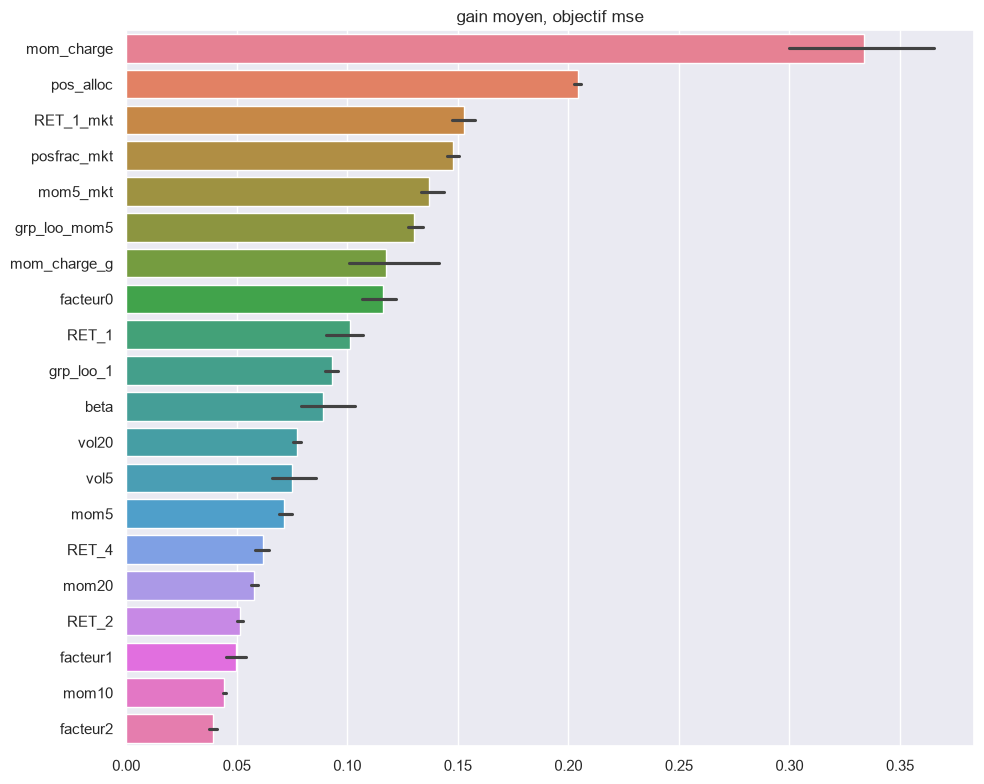

CPU times: user 1.35 s, sys: 194 ms, total: 1.54 s
Wall time: 1.6 s


In [22]:
%%time
noms = list(prepare(F_train.head(1), fold != 0,
                    allocation[:1], groupe[:1], ret1[:1], ts_train[:1]).columns)
importances = pd.DataFrame([m.feature_importance(importance_type='gain') for m in modeles['mse']],
                           columns=noms)
ordre = importances.mean(0).sort_values(ascending=False).index[:20]

plt.figure(figsize=(10, 8))
sns.barplot(data=importances.loc[:, ordre], orient='h', order=ordre)
plt.title('gain moyen, objectif mse')
plt.tight_layout()
plt.show()

RET_1 domine largement, suivi des agrégats de journée et des moyennes de groupe. Cela
recoupe ce qu'on voyait sur les signaux bruts, le modèle exploite surtout le momentum à un
jour et le situe par rapport au reste de la cross-section.

### Réentraînement et soumission

In [23]:
%%time
# Plus de validation a ce stade : les chargements sont estimes sur tout le train.
tout = np.ones(len(F_train), bool)
A_train = prepare(F_train, tout, allocation, groupe, ret1, ts_train)
st_final = stats_allocation(tout)
L_f, mu_f, sd_f = facteurs_communs(tout)
A_test = ajoute_facteurs(
    ajoute_charges(F_test, st_final, allocation_test, groupe_test, ret1_test),
    L_f, mu_f, sd_f, allocation_test, ts_test)

pred_test = np.zeros(len(F_test))
for nom, (params, label, n_arbres) in objectifs.items():
    cumul = np.zeros(len(F_test))
    for graine in GRAINES:
        modele = lgbm.train(dict(params, seed=graine),
                            lgbm.Dataset(A_train, label=label), num_boost_round=n_arbres)
        cumul += modele.predict(A_test)
    pred_test += centre_reduit(cumul / len(GRAINES))

M_train = np.nan_to_num(A_train.drop(columns='GROUP').to_numpy(float))
M_test  = np.nan_to_num(A_test.drop(columns='GROUP').to_numpy(float))
scaler_final = StandardScaler().fit(M_train)
ridge_final = Ridge(alpha=1000).fit(scaler_final.transform(M_train), y)
pred_test += centre_reduit(ridge_final.predict(scaler_final.transform(M_test)))

CPU times: user 12min 49s, sys: 6.9 s, total: 12min 56s
Wall time: 3min 29s


In [24]:
%%time
submission = pd.DataFrame({'ROW_ID': F_test.index, 'prediction': (pred_test > 0).astype(int)})

assert list(submission.ROW_ID) == list(sample_submission.ROW_ID)
assert submission.prediction.isin([0, 1]).all()
assert len(submission) == len(sample_submission)

submission.to_csv('submission.csv', index=False)
print(len(submission), 'lignes,', round(submission.prediction.mean(), 4), 'de predictions positives')
submission.head()

31870 lignes, 0.4928 de predictions positives
CPU times: user 46.2 ms, sys: 10.3 ms, total: 56.5 ms
Wall time: 63 ms


,ROW_ID,prediction
0,527073,1
1,527074,0
2,527075,0
3,527076,0
4,527077,0


### Environnement et duree totale

In [25]:
%%time
import numpy, pandas, scipy, sklearn, lightgbm, matplotlib, seaborn
print('python      ', sys.version.split()[0], '|', platform.platform())
for m in [numpy, pandas, scipy, sklearn, lightgbm, matplotlib, seaborn]:
    print(f'{m.__name__:12s}', m.__version__)
duree = time.time() - DEBUT
print()
print('duree totale du notebook : %d min %02d s' % (duree // 60, duree % 60))

python       3.12.0 | macOS-14.7.3-x86_64-i386-64bit
numpy        2.5.3
pandas       3.0.5
scipy        1.18.1
sklearn      1.9.1
lightgbm     4.7.0
matplotlib   3.11.2
seaborn      0.13.2

duree totale du notebook : 41 min 45 s
CPU times: user 1.11 ms, sys: 5.89 ms, total: 7 ms
Wall time: 10.2 ms


### Lire les deux classements

Le classement public et le classement privé racontent deux histoires très différentes. En
public les premiers scores dépassent 0.70, en privé le meilleur est à 0.5504 et le peloton
tient entre 0.5259 et 0.5320.

Ce ne sont pas des périodes différentes qui expliquent l'écart, ce sont les mêmes
participants. Certains apparaissent dans les deux classements, avec près de 0.67 en public
et 0.55 en privé, ou 0.61 en public et 0.53 en privé.

Le mécanisme est connu : le score public est renvoyé à chaque soumission, le nombre de
soumissions n'est pas limité, et le sous-ensemble public est petit. En retournant des blocs
de prédictions et en lisant la variation du score, on finit par reconstruire les étiquettes
de ce sous-ensemble. Trois éléments vont dans ce sens. Les scores publics forment un
continuum de 0.58 à 0.73, alors qu'une fuite exploitable donnerait à tout le monde le même
score très élevé. L'escalade se concentre sur quelques semaines. Et la recherche de fuite
menée plus haut ne trouve rien : aucune date de test ne partage la moindre journée réelle
avec le reste du jeu de données.

Rien de tout cela ne se transpose au classement privé. C'est donc lui qu'on vise, et l'ordre
de grandeur à battre est 0.5504.

### Ce qui a été écarté

Récupérer la cible du test par le chaînage des dates. La chaîne se reconstruit parfaitement
sur l'entraînement mais les dates de test n'ont aucune voisine à moins de douze jours. Un
test complémentaire, comparant la signature cross-sectionnelle de chaque journée réelle
contenue dans chaque ligne indépendamment de tout alignement de fenêtre, confirme : à
l'intérieur du train 3640 signatures sur 4000 trouvent une correspondance, avec une
corrélation médiane de 0.9933 ; pour le test, 6 sur 2400, et une médiane à 0.56.

Décaler le seuil de décision. Testé du quantile 0.40 au quantile 0.60, sans effet.

Élargir le jeu de variables. Une version à 136 variables descend à 0.5193 contre 0.5214 pour
une version à 105, le signal ne supporte pas la dimension.

Transformer la cible, en winsorisant ou en passant par un rang cross-sectionnel. Les écarts
restent dans le bruit, entre 0.5230 et 0.5234 contre 0.5231 pour la cible brute.

L'interaction du momentum avec le turnover. L'intuition dit qu'un turnover élevé raccourcit
l'horizon et devrait donner du reversal. Mesuré par quintile de turnover, la corrélation
entre RET_1 et la cible reste plate, de 0.079 à 0.089, sans ordre. L'effet n'existe pas ici.

Les autres colonnes comme source de fuite. Ordre des identifiants de ligne, doublons exacts
entre train et test, nombre de décimales, nombre d'allocations par date, absence des
colonnes : tout a été testé, rien ne dépasse le bruit. La seule exception utile est la
présence de SIGNED_VOLUME_1, qui décale le taux de positifs de 0.5033 à 0.5179 et qui est
gardée comme variable.

### Limites

L'écart type de l'accuracy entre les cinq folds est de 0.004 à 0.005, et le test ne compte
que 120 dates. Un écart inférieur à un point entre deux modèles n'est pas interprétable.

Le bloc de test est isolé dans le temps. Rien ne permet de savoir s'il précède ou suit
l'entraînement, les labels étant permutés. Le momentum à un jour, qui porte l'essentiel du
signal, peut y être plus faible qu'ailleurs.